Minimum LST: 26.03 °C
Maximum LST: 58.47 °C
Mean LST: 34.68 °C


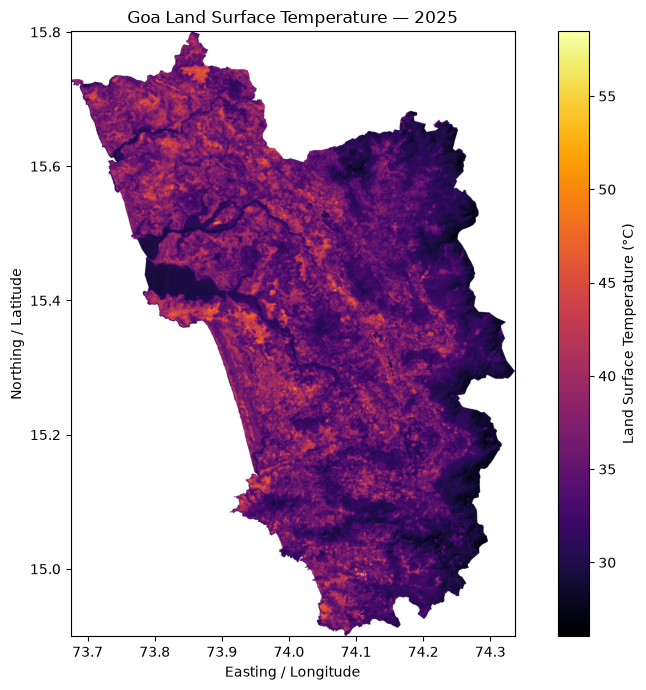

In [1]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Read the 2025 Landsat data
file_path = "Goa_Landsat_2025.tif"

with rasterio.open(file_path) as src:
    st_dn = src.read(1).astype("float32")
    bounds = src.bounds
    nodata = src.nodata

# Mask fill and invalid values
valid = np.isfinite(st_dn) & (st_dn != 0)

if nodata is not None:
    valid &= (st_dn != nodata)

# Convert ST_B10 stored values to Kelvin
lst_kelvin = st_dn * 0.00341802 + 149.0

# Convert Kelvin to Celsius
lst_celsius = lst_kelvin - 273.15
lst_celsius[~valid] = np.nan

# Print statistics
print(f"Minimum LST: {np.nanmin(lst_celsius):.2f} °C")
print(f"Maximum LST: {np.nanmax(lst_celsius):.2f} °C")
print(f"Mean LST: {np.nanmean(lst_celsius):.2f} °C")

# Plot LST map
plt.figure(figsize=(9, 7))

plt.imshow(
    lst_celsius,
    cmap="inferno",
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper"
)

plt.colorbar(label="Land Surface Temperature (°C)")
plt.title("Goa Land Surface Temperature — 2025")
plt.xlabel("Easting / Longitude")
plt.ylabel("Northing / Latitude")
plt.tight_layout()
plt.show()
